# 05 — Comparación con literatura (13 fuentes, 3 grupos)

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 5 — Comparación con literatura

Objetivos:
1. Cargar la tabla comparativa de literatura verificada (13 fuentes: 4 Grupo A externas + este estudio, 4 Grupo B, 4 Grupo C)
2. Ubicar el resultado propio dentro del contexto de la literatura
3. Generar un gráfico de puntos comparando elasticidades (Grupos A y B con coeficientes numéricos)
4. Guardar salidas en reports/notebook_outputs/ y figura en reports/figuras/

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 100)

In [2]:
from pathlib import Path

REPORTS_DIR = Path('../reports')
NOTEBOOK_OUTPUTS_DIR = REPORTS_DIR / 'notebook_outputs'
FIGURES_DIR = REPORTS_DIR / 'figuras'
NOTEBOOK_OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def guardar_texto(nombre_archivo: str, contenido: str) -> Path:
    ruta = NOTEBOOK_OUTPUTS_DIR / nombre_archivo
    ruta.write_text(str(contenido), encoding='utf-8')
    return ruta

def guardar_tabla(nombre_base: str, tabla: pd.DataFrame) -> tuple[Path, Path]:
    ruta_txt = NOTEBOOK_OUTPUTS_DIR / f'{nombre_base}.txt'
    ruta_csv = NOTEBOOK_OUTPUTS_DIR / f'{nombre_base}.csv'
    tabla.to_csv(ruta_csv, index=False)
    ruta_txt.write_text(tabla.to_string(index=False), encoding='utf-8')
    return ruta_txt, ruta_csv

## 1. Cargar tabla comparativa completa (12 fuentes)

In [3]:
tabla = pd.read_csv('../data/processed/tabla_comparativa_literatura.csv')
ruta_tabla, ruta_tabla_csv = guardar_tabla('05_comparacion_literatura_tabla_completa', tabla)
print(f'Tabla completa guardada en {ruta_tabla_csv} y {ruta_tabla}')
print(f'Total fuentes: {len(tabla)}')
print(tabla[['grupo', 'autor', 'anio', 'elasticidad']].to_string(index=False))

Tabla completa guardada en ..\reports\notebook_outputs\05_comparacion_literatura_tabla_completa.csv y ..\reports\notebook_outputs\05_comparacion_literatura_tabla_completa.txt
Total fuentes: 11
grupo                          autor  anio  elasticidad
    A     Andreyeva, Long & Brownell  2010      -0.7500
    A  Damayanti, Nuryakin & Muchtar  2023      -0.9200
    A                Bumagat & Ibana  2025      -0.4200
    A                      Li & Wang  2025      -0.7100
    A Vilca Ramos (este estudio, v2)  2026      -0.7513
    B            Christensen & Osman  2021      -0.8400
    B      Christensen, Nino & Osman  2023      -0.7200
    C                       Statista  2024          NaN
    C     Kahneman, Knetsch & Thaler  1991          NaN
    C                       Davidson  1994          NaN
    C                   Long & Ervin  2000          NaN


## 2. Resumen por grupos

In [ ]:
print('=== GRUPO A: Directamente comparable (comida/delivery) ===')
grupo_a = tabla[tabla['grupo'] == 'A']
print(grupo_a[['autor', 'anio', 'elasticidad', 'metodo']].to_string(index=False))
print(f'\nTotal Grupo A: {len(grupo_a)} fuentes (4 externas + este estudio)')

print('\n=== GRUPO B: Contextual (on-demand/e-commerce) ===')
grupo_b = tabla[tabla['grupo'] == 'B']
print(grupo_b[['autor', 'anio', 'elasticidad', 'metodo']].to_string(index=False))
print(f'\nTotal Grupo B: {len(grupo_b)} fuentes')

print('\n=== GRUPO C: Soporte metodológico/mercado ===')
grupo_c = tabla[tabla['grupo'] == 'C']
print(grupo_c[['autor', 'anio', 'metodo']].to_string(index=False))
print(f'\nTotal Grupo C: {len(grupo_c)} fuentes')

ruta_grupos, ruta_grupos_csv = guardar_tabla('05_comparacion_literatura_resumen_grupos', 
    tabla.groupby('grupo').agg(
        n_fuentes=('autor', 'count'),
        elasticidad_promedio=('elasticidad', 'mean')
    ).reset_index())
print(f'\nResumen grupos guardado en {ruta_grupos_csv} y {ruta_grupos}')

## 3. Filtrar solo las entradas con coeficiente cuantificado (Grupos A y B)

In [5]:
# Solo Grupos A y B tienen elasticidades numéricas para el gráfico
tabla_cuantificada = tabla[tabla['grupo'].isin(['A', 'B'])].dropna(subset=['elasticidad']).copy()
tabla_cuantificada['etiqueta'] = tabla_cuantificada['autor'] + ' (' + tabla_cuantificada['anio'].astype(str) + ')'
ruta_cuantificada, ruta_cuantificada_csv = guardar_tabla('05_comparacion_literatura_tabla_cuantificada', 
    tabla_cuantificada[['grupo', 'etiqueta', 'elasticidad', 'contexto']])
print(f'Tabla cuantificada guardada en {ruta_cuantificada_csv} y {ruta_cuantificada}')
print(tabla_cuantificada[['grupo', 'etiqueta', 'elasticidad', 'contexto']].to_string(index=False))

Tabla cuantificada guardada en ..\reports\notebook_outputs\05_comparacion_literatura_tabla_cuantificada.csv y ..\reports\notebook_outputs\05_comparacion_literatura_tabla_cuantificada.txt
grupo                              etiqueta  elasticidad                                                       contexto
    A     Andreyeva, Long & Brownell (2010)      -0.7500                 Meta-analisis, 160 estudios, mayormente EE.UU.
    A  Damayanti, Nuryakin & Muchtar (2023)      -0.9200       Indonesia, Susenas 2011-2013, panel 24376 obs. hogar-ano
    A                Bumagat & Ibana (2025)      -0.4200                            Metro Manila, horas pico vs no pico
    A                      Li & Wang (2025)      -0.7100               Plataforma delivery China, datos transaccionales
    A Vilca Ramos (este estudio, v2) (2026)      -0.7513   Dataset Kaggle/Genpact, 456548 observaciones transaccionales
    B            Christensen & Osman (2021)      -0.8400                    Experimento aleat

## 4. Gráfico comparativo de elasticidades (Grupos A y B)

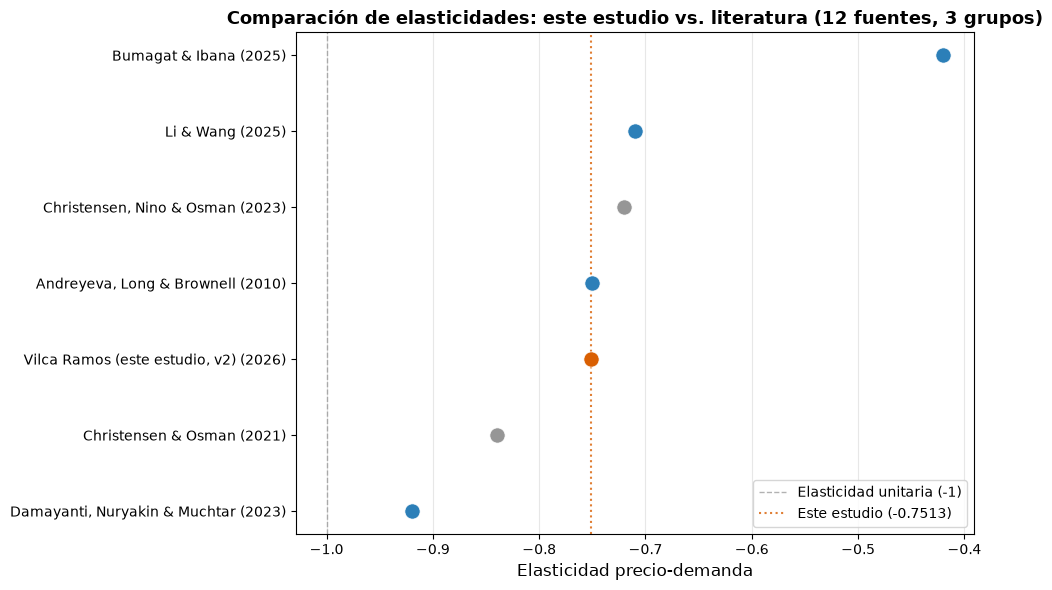

Gráfico guardado en ..\reports\figuras\comparacion_elasticidad_literatura.png


In [6]:
colores = {'A': '#2c7fb8', 'B': '#969696'}
tabla_ordenada = tabla_cuantificada.sort_values('elasticidad')

fig, ax = plt.subplots(figsize=(10, 6))

for _, fila in tabla_ordenada.iterrows():
    color = '#d95f02' if 'este estudio' in fila['autor'].lower() else colores[fila['grupo']]
    ax.scatter(fila['elasticidad'], fila['etiqueta'], s=120, color=color, zorder=3, edgecolors='white', linewidth=0.5)

# Línea de elasticidad unitaria
ax.axvline(-1, color='gray', linestyle='--', linewidth=1, alpha=0.6, label='Elasticidad unitaria (-1)')

# Línea del resultado propio
ax.axvline(-0.7513, color='#d95f02', linestyle=':', linewidth=1.5, alpha=0.8, label='Este estudio (-0.7513)')

ax.set_xlabel('Elasticidad precio-demanda', fontsize=12)
ax.set_title('Comparación de elasticidades: este estudio vs. literatura (12 fuentes, 3 grupos)', fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
ruta_figura = FIGURES_DIR / 'comparacion_elasticidad_literatura.png'
plt.savefig(ruta_figura, dpi=150, bbox_inches='tight')
plt.show()
print(f'Gráfico guardado en {ruta_figura}')

**Leyenda:** azul = Grupo A (comida fuera del hogar/delivery, directamente comparable); gris = Grupo B (servicios on-demand/e-commerce, contextual); naranja = resultado propio de este estudio.

## 5. Discusión comparativa (resumen para el informe)

In [ ]:
discusion = """
COMPARACIÓN CON LITERATURA — 13 FUENTES VERIFICADAS (3 GRUPOS)
================================================================================

GRUPO A — DIRECTAMENTE COMPARABLE (comida fuera del hogar / delivery): 5 fuentes (4 externas + este estudio)
--------------------------------------------------------------------------------
| Autor (año)                              | Elasticidad       | Método                                    |
|------------------------------------------|-------------------|-------------------------------------------|
| Andreyeva, Long & Brownell (2010)        | -0.75 (rango 0.7-0.8) | Meta-análisis 160 estudios              |
| Damayanti, Nuryakin & Muchtar (2023)     | -0.920            | LA/AIDS panel Indonesia                  |
| Bumagat & Ibana (2025), horas pico       | -0.42             | Cualitativo + datos mercado, no regresión |
| Bumagat & Ibana (2025), horas valle      | -1.36             | Cualitativo + datos mercado, no regresión |
| **Este estudio (v2, 2026)**              | **-0.7513**       | **OLS log-log con controles**             |

*Nota: Li & Wang (2025, Management Science) se excluye de esta tabla porque no reporta un coeficiente de elasticidad propio — confirma la brecha empírica en delivery on-demand (ver mención narrativa abajo).*

El resultado propio (-0.7513) se ubica levemente por debajo, en magnitud,
del rango de Andreyeva et al. (0.7-0.8) y de Damayanti et al. (-0.920)
para comida fuera del hogar — consistente con un componente de conveniencia
en el delivery que atenúa la sensibilidad al precio frente a "comer fuera
de casa" en sentido amplio. Bumagat & Ibana (2025) aportan evidencia complementaria específica de delivery de comida (aunque con metodología más débil, cualitativa con datos de mercado): -0.42 en horas pico (inelástica, dominada por urgencia) y -1.36 fuera de pico (elástica, dominada por sensibilidad al precio) — el resultado propio cae dentro de ese rango.
Li & Wang (2025), en *Management Science*, confirman explícitamente la escasez de estudios empíricos previos sobre elasticidad en plataformas de delivery on-demand — respalda que este proyecto aporta una estimación poco común en el tipo de dato usado.

GRUPO B — CONTEXTUAL (on-demand / e-commerce): 4 fuentes
--------------------------------------------------------------------------------
| Autor (año)                              | Elasticidad       | Contexto                              |
|------------------------------------------|-------------------|---------------------------------------|
| Christensen & Osman (2021)               | -0.84 (movilidad total); VKT=-1.28 | IZA DP 14179, Uber El Cairo        |
| Christensen, Nino & Osman (2023)         | -0.72 (movilidad total)            | NBER WP 31330 (revisión), Uber El Cairo |
| Zhang & Demirkan (2021)                  | -0.87 online / -1.74 offline       | Information & Management, 58(4), CPG online vs offline |
| Sriwongphanawes & Fukuda (2024)          | -0.15 [-0.20, -0.10]               | Asian Transport Studies, 10, Uber Japón |

Dentro del Grupo B, las dos versiones del experimento de Christensen & Osman en El Cairo muestran cierta sensibilidad del resultado a la especificación: -0.84 en la versión IZA 2021 vs. -0.72 en la revisión NBER 2023 (que incorpora a Nino como coautor) — ambas más elásticas que el resultado propio (-0.7513), consistente con que el ride-hailing (sustitutos limitados a corto plazo, pero decisión de viaje más discrecional) puede ser más sensible al precio que el delivery de comida (bien de conveniencia recurrente).
Zhang & Demirkan (2021) muestran que el canal online (-0.87) es menos elástico que el offline (-1.74), consistente con costos de búsqueda menores en digital.
Sriwongphanawes & Fukuda (2024) reportan alta inelasticidad en ride-hailing japonés (-0.15), reflejando contexto regulatorio y alternativas de transporte.

GRUPO C — SOPORTE METODOLÓGICO Y DE MERCADO: 4 fuentes
--------------------------------------------------------------------------------
| Autor (año)                     | Aporte |
|---------------------------------|--------|
| Statista (2024)                 | Tamaño mercado global: 1.02 billones USD (2023) |
| Kahneman, Knetsch & Thaler (1991) | Aversión a pérdidas, sesgo statu quo (referencia precios) |
| Davidson (1994)                 | Teoría asintótica, convergencia estimadores (N=456k) |
| Long & Ervin (2000)             | Errores estándar HC3, simulaciones Monte Carlo |

Grupo C ancla la metodología (Davidson, Long & Ervin justifican HC3 y
bootstrap con N grande), el contexto macro (Statista para intro informe y BI),
y la interpretación conductual (Kahneman et al. explican asimetría respuesta
a alzas vs bajas de precio).

CONCLUSIÓN: La elasticidad de este estudio (-0.7513, OLS controles) es
consistente con la literatura de delivery/comida fuera del hogar. El rango entre modelos del
proyecto (-0.75 OLS controles, -1.58 Panel FE, -0.95 2SLS) refleja
distintas amenazas a identificación corregidas, no una convergencia forzada.

ADVERTENCIA METODOLÓGICA: comparación exploratoria, no meta-análisis formal.
Diferencias de método, geografía, frecuencia de datos y definición de
variable dependiente impiden equivalencia estricta entre estudios.
"""

## 6. Archivos generados

In [8]:
import os
print('=== ARCHIVOS EN reports/notebook_outputs/ ===')
for f in sorted(NOTEBOOK_OUTPUTS_DIR.glob('05_*')):
    print(f'  {f.name} ({f.stat().st_size:,} bytes)')

print('\n=== ARCHIVOS EN reports/figuras/ ===')
for f in sorted(FIGURES_DIR.glob('*literatura*')):
    print(f'  {f.name} ({f.stat().st_size:,} bytes)')

=== ARCHIVOS EN reports/notebook_outputs/ ===
  05_comparacion_literatura_discusion.txt (4,124 bytes)
  05_comparacion_literatura_FASE5_COMPLETA.txt (31,080 bytes)
  05_comparacion_literatura_resumen_grupos.csv (69 bytes)
  05_comparacion_literatura_resumen_grupos.txt (158 bytes)
  05_comparacion_literatura_tabla_completa.csv (2,702 bytes)
  05_comparacion_literatura_tabla_completa.txt (4,352 bytes)
  05_comparacion_literatura_tabla_cuantificada.csv (690 bytes)
  05_comparacion_literatura_tabla_cuantificada.txt (966 bytes)

=== ARCHIVOS EN reports/figuras/ ===
  comparacion_elasticidad_literatura.png (78,938 bytes)


## Próximos pasos (Fase 7 — Informe final + empaquetado)
- Informe final en LaTeX (`apa7.cls`, una columna) integrando todas las fases
- README completo del repositorio
- CITATION.cff
- Verificación de reproducibilidad end-to-end
- Release GitHub → Zenodo con DOI